# 03 · Métricas de centralidade

**Objetivo:** entender, calcular à mão e interpretar as métricas estruturais que o projeto usa como atributos (`src/pixfraud/features.py`): grau, proximidade, intermediação, PageRank, coeficiente de agrupamento e reciprocidade.

**Leitura de apoio:** Easley & Kleinberg, cap. 3 (agrupamento e laços fracos) e cap. 14 (PageRank); Brandes (2001), o algoritmo de intermediação usado pelo NetworkX.

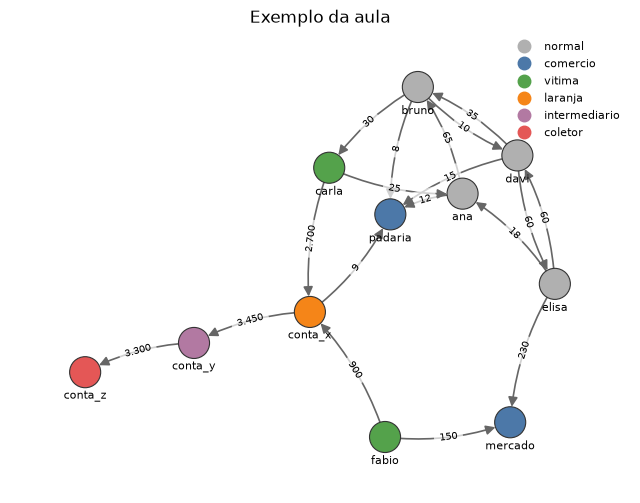

In [1]:
import time

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

from pixfraud.graph import adjacency_matrix, build_graph, graph_from_csv
from pixfraud.simulation import load_dataset
from pixfraud.visualization import draw_graph

A = graph_from_csv("dados/exemplo_transacoes.csv")
papel_ex = pd.read_csv("dados/exemplo_contas.csv").set_index("account_id")["role"]
nx.set_node_attributes(A, papel_ex.to_dict(), "role")
draw_graph(A, title="Exemplo da aula");

## 1. Centralidade de grau

A mais simples: quantas conexões a conta tem, dividido pelo máximo possível, $n - 1$:

$$C_D^{\text{in}}(v) = \frac{d^-(v)}{n-1} \qquad C_D^{\text{out}}(v) = \frac{d^+(v)}{n-1}$$

In [2]:
pd.DataFrame({
    "entrada": nx.in_degree_centrality(A),
    "saída": nx.out_degree_centrality(A),
}).sort_values("entrada", ascending=False).round(3)

,entrada,saída
padaria,0.4,0.0
ana,0.2,0.2
bruno,0.2,0.3
davi,0.2,0.3
conta_x,0.2,0.2
mercado,0.2,0.0
carla,0.1,0.2
conta_y,0.1,0.1
conta_z,0.1,0.0
elisa,0.1,0.3


## 2. Proximidade (*closeness*)

A proximidade mede o quão perto uma conta está das outras: é o inverso da distância média. Num dígrafo, o NetworkX usa as distâncias **de chegada** $d(u, v)$, de cada $u$ até $v$. Como nem todos alcançam $v$, aplica a correção de Wasserman e Faust. Com $r(v)$ = número de contas que alcançam $v$ e $N$ = total de contas:

$$C_C(v) = \frac{r(v)}{\sum_{u} d(u, v)} \cdot \frac{r(v)}{N - 1}$$

In [3]:
pd.Series(nx.closeness_centrality(A)).sort_values(ascending=False).round(3)

padaria    0.490
ana        0.267
bruno      0.267
conta_x    0.257
conta_y    0.233
davi       0.229
mercado    0.225
conta_z    0.221
carla      0.200
elisa      0.160
fabio      0.000
dtype: float64

A proximidade não está entre os atributos do projeto: é cara em grafos grandes. Pode ser um candidato a testar.

## 3. Intermediação (*betweenness*)

A intermediação mede o quanto uma conta está **no meio do caminho** entre outras. Para cada par $(s, t)$, seja $\sigma_{st}$ o nº de caminhos mínimos de $s$ a $t$ e $\sigma_{st}(v)$ quantos deles passam por $v$:

$$C_B(v) = \sum_{s \neq v \neq t} \frac{\sigma_{st}(v)}{\sigma_{st}}$$

Na versão normalizada, num dígrafo, divide-se por $(n-1)(n-2)$, o número de pares ordenados que não incluem $v$.

Numa lavagem em cadeia, as contas intermediárias ficam, por construção, no caminho entre as laranjas e o coletor.

### Calculando à mão

Na cadeia $a \to b \to c \to d$:

- por $b$ passam os caminhos $a \to c$ e $a \to d$, então $C_B(b) = 2$;
- por $c$ passam $a \to d$ e $b \to d$, então $C_B(c) = 2$;
- $a$ e $d$ estão nas pontas: $C_B = 0$.

Normalizando: $2 / (3 \cdot 2) = 1/3$.

In [4]:
cadeia = nx.path_graph(["a", "b", "c", "d"], create_using=nx.DiGraph)
print("não normalizada:", nx.betweenness_centrality(cadeia, normalized=False))
print("normalizada:    ", nx.betweenness_centrality(cadeia))

não normalizada: {'a': 0.0, 'b': 2.0, 'c': 2.0, 'd': 0.0}
normalizada:     {'a': 0.0, 'b': 0.3333333333333333, 'c': 0.3333333333333333, 'd': 0.0}


Quando há caminhos mínimos alternativos, o crédito é dividido. No losango $s \to x \to t$, $s \to y \to t$ existem 2 caminhos mínimos de $s$ a $t$, um por $x$ e outro por $y$. Cada um recebe $1/2$:

In [5]:
losango = nx.DiGraph([("s", "x"), ("s", "y"), ("x", "t"), ("y", "t")])
nx.betweenness_centrality(losango, normalized=False)

{'s': 0.0, 'x': 0.5, 'y': 0.5, 't': 0.0}

No exemplo da aula:

In [6]:
pd.Series(nx.betweenness_centrality(A)).sort_values(ascending=False).round(3)

bruno      0.200
conta_x    0.150
carla      0.144
davi       0.100
ana        0.083
conta_y    0.078
elisa      0.056
padaria    0.000
conta_z    0.000
mercado    0.000
fabio      0.000
dtype: float64

### Custo e aproximação

O algoritmo de Brandes calcula a intermediação exata em $O(nm)$ num grafo sem pesos. No dataset sintético (2.142 vértices, ~32 mil arestas) são dezenas de milhões de passos. Por isso o projeto usa uma **aproximação**: sorteia $k$ vértices de origem (`betweenness_k` em `configs/experimento.yaml`). Quão boa ela é?

*(A célula abaixo leva uns 20 segundos, por causa do cálculo exato.)*

In [7]:
contas, tx = load_dataset("../data/synthetic")
G = build_graph(tx, contas["account_id"])
papel = contas.set_index("account_id")["role"]

intermediacao = {}
for k in [100, 500, None]:
    inicio = time.perf_counter()
    intermediacao[k or "exata"] = pd.Series(nx.betweenness_centrality(G, k=k, seed=42))
    print(f"k = {k or 'todos'}: {time.perf_counter() - inicio:.1f} s")

exata = intermediacao["exata"]
top50 = set(exata.nlargest(50).index)
for k in [100, 500]:
    aprox = intermediacao[k]
    print(f"k = {k}: correlação de Spearman = {aprox.corr(exata, method='spearman'):.3f}, "
          f"top-50 em comum = {len(top50 & set(aprox.nlargest(50).index))}/50")

k = 100: 0.7 s


k = 500: 3.5 s


k = todos: 15.5 s


k = 100: correlação de Spearman = 0.791, top-50 em comum = 20/50
k = 500: correlação de Spearman = 0.937, top-50 em comum = 35/50


## 4. PageRank

Imagine uma "moeda" passeando pela rede. A cada passo, com probabilidade $\alpha$ (tipicamente 0,85), ela segue um Pix que sai da conta atual, escolhido com probabilidade proporcional ao valor. Com probabilidade $1 - \alpha$, ela "salta" para uma conta qualquer. O **PageRank** de uma conta é a fração do tempo que a moeda passa nela, a longo prazo. Contas que recebem muito dinheiro de contas que também recebem muito dinheiro ficam com PageRank alto, como os coletores.

Seja $P$ a matriz de transição (a matriz de adjacência ponderada com cada linha dividida pela sua soma). O vetor $r$ é atualizado assim:

$$r_{t+1} = \alpha \left( r_t P + \frac{s_t}{n}\mathbf{1} \right) + \frac{1 - \alpha}{n}\mathbf{1}$$

em que $s_t$ é a massa parada nas contas **sem saída** (*dangling*, como o coletor), redistribuída igualmente entre todas. Repetindo até convergir, temos o **método da potência**:

In [8]:
def pagerank_manual(G, alpha=0.85, weight="amount", iteracoes=100):
    M = adjacency_matrix(G, weight=weight).to_numpy()
    n = len(M)
    soma = M.sum(axis=1, keepdims=True)
    sem_saida = soma[:, 0] == 0
    P = np.divide(M, soma, out=np.zeros_like(M), where=soma > 0)
    r = np.full(n, 1 / n)
    for _ in range(iteracoes):
        r = alpha * (r @ P + r[sem_saida].sum() / n) + (1 - alpha) / n
    return pd.Series(r, index=list(G.nodes))


comparacao = pd.DataFrame({
    "manual": pagerank_manual(A),
    "networkx": pd.Series(nx.pagerank(A, weight="amount")),
}).sort_values("manual", ascending=False)
print("iguais?", np.allclose(comparacao["manual"], comparacao["networkx"], atol=1e-5))
comparacao.round(4)

iguais? True


,manual,networkx
conta_z,0.1703,0.1704
conta_y,0.1551,0.1551
conta_x,0.1376,0.1376
mercado,0.0868,0.0868
bruno,0.0864,0.0864
carla,0.0844,0.0844
elisa,0.0687,0.0687
davi,0.0652,0.0652
padaria,0.0644,0.0644
ana,0.0426,0.0426


Com peso `amount`, o PageRank mostra para onde o dinheiro escoa: o coletor `conta_z` fica no topo. Sem peso (`weight=None`), só a estrutura importa:

In [9]:
pd.DataFrame({
    "com valor": pd.Series(nx.pagerank(A, weight="amount")),
    "sem valor": pd.Series(nx.pagerank(A, weight=None)),
}).sort_values("com valor", ascending=False).round(4)

,com valor,sem valor
conta_z,0.1704,0.1094
conta_y,0.1551,0.0798
conta_x,0.1376,0.0897
mercado,0.0868,0.0784
bruno,0.0864,0.1060
carla,0.0844,0.0717
elisa,0.0687,0.0673
davi,0.0652,0.0907
padaria,0.0644,0.1742
ana,0.0426,0.0911


## 5. Coeficiente de agrupamento

O coeficiente de agrupamento local de $v$ (no grafo não direcionado) é a fração dos pares de vizinhos de $v$ que também estão ligados entre si, ou seja, quantos "triângulos" se fecham. Com $T(v)$ = nº de triângulos que contêm $v$:

$$C(v) = \frac{2\,T(v)}{d(v)\,(d(v)-1)}$$

Amigos de amigos costumam ser amigos (Easley & Kleinberg, cap. 3). Já uma laranja recebe de vítimas que não se conhecem, então o agrupamento dela é baixo. A exceção é o golpe do WhatsApp clonado, em que as vítimas são contatos da mesma pessoa.

In [10]:
pd.Series(nx.clustering(A.to_undirected())).sort_values(ascending=False).round(3)

bruno      0.500
ana        0.333
padaria    0.333
carla      0.333
davi       0.333
conta_x    0.000
conta_y    0.000
conta_z    0.000
elisa      0.000
mercado    0.000
fabio      0.000
dtype: float64

## 6. Reciprocidade

A reciprocidade é a fração das arestas de uma conta que têm "volta" ($u \to v$ e $v \to u$). Amigos trocam Pix nos dois sentidos; o dinheiro do golpe só vai.

In [11]:
pd.Series(nx.reciprocity(A, A.nodes)).sort_values(ascending=False).round(3)

davi       0.8
elisa      0.5
bruno      0.4
padaria    0.0
ana        0.0
conta_x    0.0
carla      0.0
conta_y    0.0
conta_z    0.0
mercado    0.0
fabio      0.0
dtype: float64

## 7. As métricas no dataset sintético

Compare a distribuição de cada métrica por papel da conta. As três primeiras colunas estão em escala logarítmica, porque as métricas têm cauda pesada.

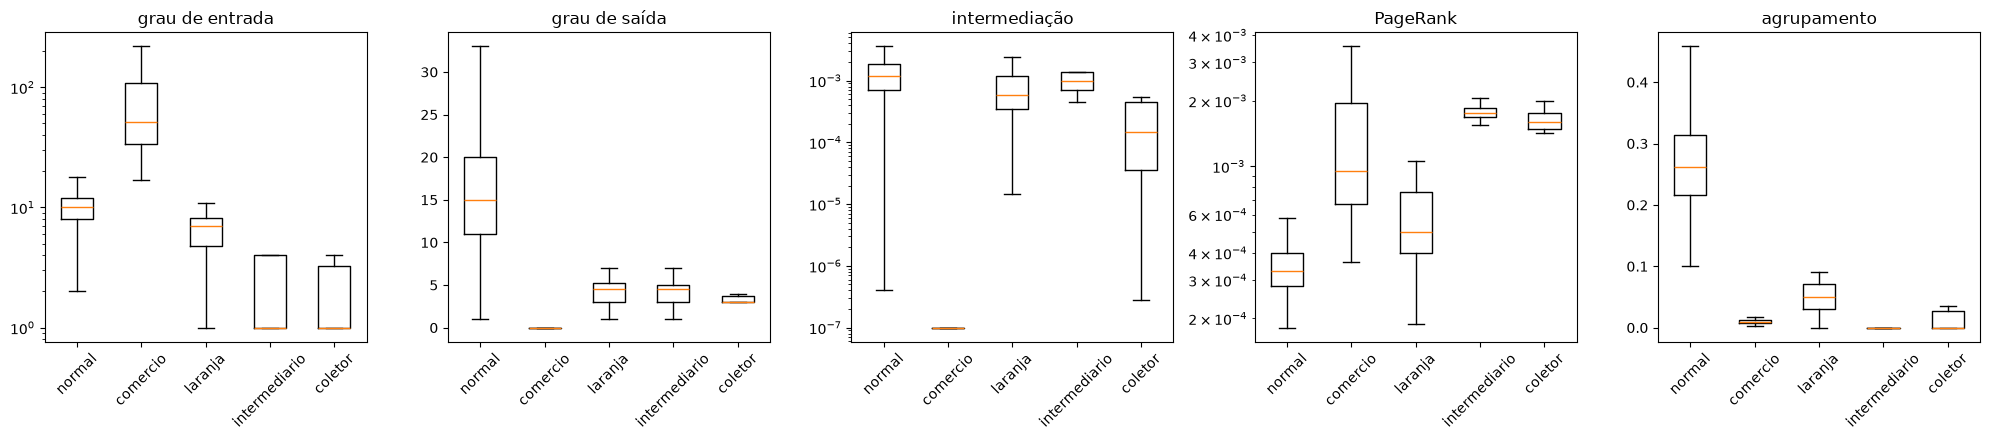

In [12]:
metricas = pd.DataFrame({
    "grau de entrada": pd.Series(dict(G.in_degree())),
    "grau de saída": pd.Series(dict(G.out_degree())),
    "intermediação": intermediacao[500],
    "PageRank": pd.Series(nx.pagerank(G, weight="amount")),
    "agrupamento": pd.Series(nx.clustering(G.to_undirected())),
})
ordem = ["normal", "comercio", "laranja", "intermediario", "coletor"]

fig, axes = plt.subplots(1, 5, figsize=(20, 4.5))
for ax, coluna in zip(axes, metricas.columns):
    log = coluna in ("intermediação", "PageRank", "grau de entrada")
    dados = [metricas.loc[papel == p, coluna] + (1e-7 if log else 0) for p in ordem]
    ax.boxplot(dados, tick_labels=ordem, showfliers=False)
    if log:
        ax.set_yscale("log")
    ax.set_title(coluna)
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()

In [13]:
metricas.groupby(papel).median().loc[ordem]

,grau de entrada,grau de saída,intermediação,PageRank,agrupamento
role,,,,,
normal,10.0,15.0,0.001187,0.000332,0.261905
comercio,51.5,0.0,0.000000,0.000949,0.010001
laranja,7.0,4.5,0.000595,0.000499,0.049545
intermediario,1.0,4.5,0.000968,0.001757,0.000000
coletor,1.0,3.0,0.000146,0.001590,0.000000


**Para pensar:**

- Qual métrica separa melhor cada papel de fraude das contas normais?
- Na cadeia isolada, os intermediários têm a maior intermediação possível. Aqui, porém, a mediana deles **não** é maior que a das contas normais. Por quê? Pista: numa rede com 2 mil contas, quantos caminhos mínimos terminam no coletor, comparados com os que atravessam uma pessoa comum dentro de um círculo de amigos? O que isso diz sobre usar a intermediação "pura" como atributo?
- Em quais métricas os comércios se parecem com os coletores? Isso explica parte dos falsos positivos do experimento (`reports/results/metricas.csv`).

## Exercícios

1. **À mão.** Calcule a intermediação não normalizada de cada vértice na "gravata-borboleta" $a \to m$, $b \to m$, $m \to c$, $m \to d$. Confira com o NetworkX.
2. **PageRank e $\alpha$.** Rode `pagerank_manual` com $\alpha = 0{,}5$ e compare com `nx.pagerank(A, alpha=0.5, weight="amount")`. O que acontece com o PageRank de `conta_z` quando $\alpha$ diminui? Por quê?
3. **Convergência.** Modifique `pagerank_manual` para parar quando a soma das diferenças absolutas entre duas iterações for menor que $10^{-8}$ e conte quantas iterações foram necessárias.
4. **Reciprocidade por papel.** No dataset sintético, calcule a reciprocidade de cada conta (ignore as isoladas) e a mediana por papel. As laranjas devolvem dinheiro?
5. **Pensando no projeto.** Qual métrica deste notebook que ainda não está em `features.py` você acrescentaria aos atributos? Justifique com os dados.

In [14]:
# seu código aqui